1. Create a Google Colab notebook.
2. Use 🤗 Datasets to load the train split of the facebook/voxpopuli dataset in language of your choice in streaming mode.
3. Get the third example from the train part of the dataset and explore it. Given the features that this example has, what kinds of audio tasks can you use this dataset for?
4. Plot this example’s waveform and spectrogram.
5. Go to 🤗 Hub, explore pretrained models and find one that can be used for automatic speech recognition for the language that you have picked earlier. Instantiate a corresponding pipeline with the model you found, and transcribe the example.
6. Compare the transcription that you get from the pipeline to the transcription provided in the example.

In [1]:
import datasets
from datasets import load_dataset
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

import io
import soundfile as sf
from datasets import Audio

voices = load_dataset("facebook/voxpopuli", "it", split="train", streaming=True)
voices = voices.cast_column("audio", Audio(decode=False))
print(voices)

example = next(iter(voices.skip(2).take(1)))
audio_array, sr = sf.read(io.BytesIO(example["audio"]["bytes"]))
print({k: v for k, v in example.items() if k != "audio"})



IterableDataset({
    features: ['audio_id', 'language', 'audio', 'raw_text', 'normalized_text', 'gender', 'speaker_id', 'is_gold_transcript', 'accent'],
    num_shards: 5
})
{'audio_id': '20170516-0900-PLENARY-19-it_20170516-21:06:09_2', 'language': 5, 'raw_text': "Tale malcontento fortissimo nei confronti del governo ha portato a una reazione scomposta, con una riduzione della libertà di espressione, l'attacco alle opposizioni e, in qualche modo, una soppressione di quelle voci che chiedono invece maggiore trasparenza e libertà.", 'normalized_text': "tale malcontento fortissimo nei confronti del governo ha portato a una reazione scomposta con una riduzione della libertà di espressione l'attacco alle opposizioni e in qualche modo una soppressione di quelle voci che chiedono invece maggiore trasparenza e libertà.", 'gender': 'male', 'speaker_id': '124812', 'is_gold_transcript': True, 'accent': 'None'}


-  array (Amplitude over time): A 1D list of floating-point numbers (typically between -1.0 and 1.0). Each number measures the air pressure (speaker cone position/loudness) of the sound wave at a tiny slice in time.
- sr / sampling_rate (Speed of snapshots): The number of audio samples recorded per second, measured in Hertz (Hz). In VoxPopuli, sr is 16,000 Hz, meaning there are 16,000 numbers in array for every 1 second of speech (so a 3-second clip has an array of length 48,000).

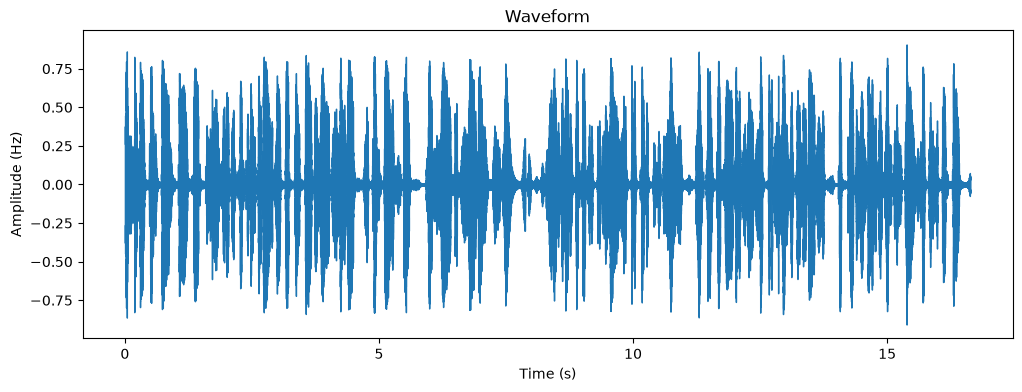

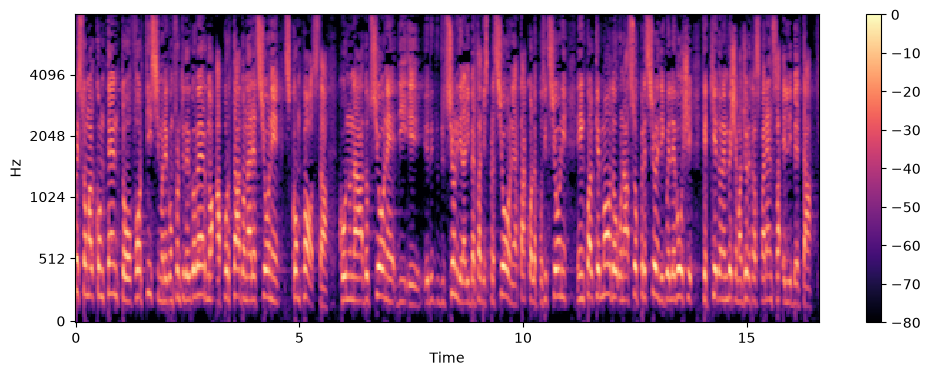

In [3]:
#waveform
plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio_array, sr=sr)
plt.title("Waveform")
plt.xlabel("Time (s)") 
plt.ylabel("Amplitude (Hz)")
plt.show()


#spectrogram 
S= librosa.feature.melspectrogram(y=audio_array, sr=sr, n_mels=128)
S_db = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(12,4))
librosa.display.specshow(S_db, x_axis="time", y_axis="mel", sr=sr)
plt.colorbar()
plt.show()

In [6]:
from transformers import pipeline

transcription_pipe = pipeline("automatic-speech-recognition", model="openai/whisper-small")
results = transcription_pipe({"array": audio_array, "sampling_rate":sr}, generate_kwargs={"language":"italian"})

print(results["text"])

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


 Questo malcontento fortissimo nei confronti del governo ha portato una reazione scomposta con una dozione di riduzioni della libertà di espressione, attacco alle posizioni e in qualche modo una soppressione di quelle voci che chiedono invece maggiore trasparenza e libertà.


In [11]:
#  compare with the dataset's transcription
import re, evaluate

norm = lambda t: re.sub(r"[^\w\s]", "", t.lower()).strip()
wer = evaluate.load("wer")
print("Reference :", example["normalized_text"])
print("Prediction:", norm(results["text"]))
print("WER:", wer.compute(predictions=[norm(results["text"])],
                          references=[norm(example["normalized_text"])]))

Reference : tale malcontento fortissimo nei confronti del governo ha portato a una reazione scomposta con una riduzione della libertà di espressione l'attacco alle opposizioni e in qualche modo una soppressione di quelle voci che chiedono invece maggiore trasparenza e libertà.
Prediction: questo malcontento fortissimo nei confronti del governo ha portato una reazione scomposta con una dozione di riduzioni della libertà di espressione attacco alle posizioni e in qualche modo una soppressione di quelle voci che chiedono invece maggiore trasparenza e libertà
WER: 0.1794871794871795
